# ResNet-56 (CIFAR-10)

In [26]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("Liczę na:", device)

Liczę na: cuda


##### 1. Dataset

In [27]:
raw = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)

indices = torch.randperm(50000, generator=torch.Generator().manual_seed(42))
train_idx, val_idx = indices[:45000], indices[45000:]

# "per-pixel mean subtracted": średni obraz 3×32×32 liczony tylko na części treningowej
MEAN_IMAGE = torch.tensor(raw.data[train_idx.numpy()].mean(axis=0) / 255.0, dtype=torch.float32).permute(2, 0, 1)

print("mean image:", tuple(MEAN_IMAGE.shape))
print("średnia per kanał:", [round(m, 4) for m in MEAN_IMAGE.mean(dim=(1, 2)).tolist()])

Files already downloaded and verified
mean image: (3, 32, 32)
średnia per kanał: [0.4917, 0.4823, 0.4467]


In [28]:
class SubtractMean:
    def __init__(self, mean_image):
        self.mean_image = mean_image

    def __call__(self, x):
        return x - self.mean_image


# padding 4 px (zerami, czyli wartością średnią), losowy crop 32×32, losowe odbicie poziome
train_transform = transforms.Compose([
    transforms.ToTensor(),
    SubtractMean(MEAN_IMAGE),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    SubtractMean(MEAN_IMAGE),
])

train_data = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
val_source = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=test_transform)
test_data = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)

train_set = Subset(train_data, train_idx)
val_set = Subset(val_source, val_idx)

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=256)
test_loader = DataLoader(test_data, batch_size=256)

print("train:", len(train_set), "| validation:", len(val_set), "| test:", len(test_data))
print("iteracji na epokę:", len(train_loader))

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
train: 45000 | validation: 5000 | test: 10000
iteracji na epokę: 352


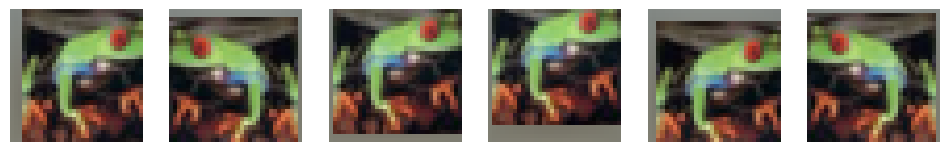

Kształt batcha: (128, 3, 32, 32)


In [29]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2))
for ax in axes:
    x, label = train_set[0]
    ax.imshow((x + MEAN_IMAGE).permute(1, 2, 0).clamp(0, 1))
    ax.axis("off")
plt.show()

images, labels = next(iter(train_loader))
print("Kształt batcha:", tuple(images.shape))

##### 2. Residual block

In [30]:
class ResidualBlock(nn.Module):
    """y = relu(F(x) + shortcut(x)),  F = BN(conv(relu(BN(conv(x)))))
    residual=False -> blok sieci plain: y = relu(F(x)), te same warstwy i parametry, bez skrótu"""

    def __init__(self, in_channels, out_channels, stride=1, residual=True):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.stride = stride
        self.extra_channels = out_channels - in_channels
        self.residual = residual

    def shortcut(self, x):
      
        if self.stride > 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.extra_channels > 0:
            x = F.pad(x, (0, 0, 0, 0, 0, self.extra_channels))
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)

In [31]:
x = torch.randn(8, 16, 32, 32)

block = ResidualBlock(16, 16)
print("identity block:    ", tuple(x.shape), "->", tuple(block(x).shape))

down = ResidualBlock(16, 32, stride=2)
s = down.shortcut(x)
print("downsampling block:", tuple(x.shape), "->", tuple(down(x).shape))
print("shortcut = x[:, :, ::2, ::2] + zerowe kanały?",
      torch.equal(s[:, :16], x[:, :, ::2, ::2]) and bool((s[:, 16:] == 0).all()))


x_pos = x.relu()
for residual in [True, False]:
    zero_block = ResidualBlock(16, 16, residual=residual)
    nn.init.zeros_(zero_block.bn2.weight)
    y = zero_block(x_pos)
    print(f"residual={residual}: F(x) = 0  ->  y == x? {torch.allclose(y, x_pos)} | y == 0? {bool((y == 0).all())}")

identity block:     (8, 16, 32, 32) -> (8, 16, 32, 32)
downsampling block: (8, 16, 32, 32) -> (8, 32, 16, 16)
shortcut = x[:, :, ::2, ::2] + zerowe kanały? True
residual=True: F(x) = 0  ->  y == x? True | y == 0? False
residual=False: F(x) = 0  ->  y == x? False | y == 0? True


##### 3. Model

In [32]:
class ResNet(nn.Module):
    def __init__(self, depth, residual=True):
        super().__init__()
        n = (depth - 2) // 6  

        def stage(in_channels, out_channels, stride):
            blocks = [ResidualBlock(in_channels, out_channels, stride, residual)]
            blocks += [ResidualBlock(out_channels, out_channels, 1, residual) for _ in range(n - 1)]
            return blocks

        layers = []
        layers += [nn.Conv2d(3, 16, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU()]
        layers += stage(16, 16, stride=1) 
        layers += stage(16, 32, stride=2) 
        layers += stage(32, 64, stride=2)  
        layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10)]
        self.layers = nn.Sequential(*layers)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")

    def forward(self, x):
        return self.layers(x)

In [33]:
for name, residual in [("ResNet-56", True), ("plain-56", False)]:
    model = ResNet(depth=56, residual=residual)
    n_layers = sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in model.modules())
    n_params = sum(p.numel() for p in model.parameters())
    out = model(images[:4])
    print(f"{name:9s} | warstwy z wagami: {n_layers} | parametry: {n_params} | output: {tuple(out.shape)}")
print("artykuł: ResNet-56 ma 0.85M parametrów, plain ma dokładnie tyle samo (skróty opcji A są bez parametrów)")

ResNet-56 | warstwy z wagami: 56 | parametry: 853018 | output: (4, 10)
plain-56  | warstwy z wagami: 56 | parametry: 853018 | output: (4, 10)
artykuł: ResNet-56 ma 0.85M parametrów, plain ma dokładnie tyle samo (skróty opcji A są bez parametrów)


##### 4. Training loop

In [34]:
LR = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    n = 0

    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = F.cross_entropy(out, y)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.detach() * len(y)
            correct += (out.argmax(1) == y).sum()
            n += len(y)

    return total_loss.item() / n, correct.item() / n


def milestones_for(epochs):
    return [epochs // 2, epochs * 3 // 4]


def train_model(model, epochs, lr=LR):
    model.to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=milestones_for(epochs), gamma=0.1)
    history = []

    for epoch in range(1, epochs + 1):
        lr_now = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = run_epoch(model, train_loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader)
        scheduler.step()

        history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc})
        print(f"epoch {epoch:2d} | lr {lr_now:.3f} | train: loss {train_loss:.3f}, accuracy {train_acc:.1%} | "
              f"val: loss {val_loss:.3f}, accuracy {val_acc:.1%}")

    return history

##### 5. Training: ResNet-56

In [35]:
EPOCHS = 20

torch.manual_seed(42)
resnet = ResNet(depth=56)
resnet_history = train_model(resnet, epochs=EPOCHS)
torch.save(resnet.state_dict(), "resnet56.pt")

epoch  1 | lr 0.100 | train: loss 2.222, accuracy 19.2% | val: loss 1.988, accuracy 24.0%
epoch  2 | lr 0.100 | train: loss 1.721, accuracy 36.0% | val: loss 1.579, accuracy 41.6%
epoch  3 | lr 0.100 | train: loss 1.443, accuracy 47.6% | val: loss 1.410, accuracy 48.7%
epoch  4 | lr 0.100 | train: loss 1.239, accuracy 55.5% | val: loss 1.437, accuracy 50.0%
epoch  5 | lr 0.100 | train: loss 1.104, accuracy 60.9% | val: loss 1.191, accuracy 59.4%
epoch  6 | lr 0.100 | train: loss 1.017, accuracy 64.0% | val: loss 1.100, accuracy 61.8%
epoch  7 | lr 0.100 | train: loss 0.938, accuracy 67.0% | val: loss 0.911, accuracy 68.0%
epoch  8 | lr 0.100 | train: loss 0.861, accuracy 70.0% | val: loss 0.882, accuracy 68.8%
epoch  9 | lr 0.100 | train: loss 0.782, accuracy 72.8% | val: loss 0.816, accuracy 72.5%
epoch 10 | lr 0.100 | train: loss 0.724, accuracy 74.8% | val: loss 0.755, accuracy 73.8%
epoch 11 | lr 0.010 | train: loss 0.581, accuracy 79.8% | val: loss 0.561, accuracy 79.9%
epoch 12 |

##### 6. Training: plain-56

In [36]:
torch.manual_seed(42)
plain = ResNet(depth=56, residual=False)
plain_history = train_model(plain, epochs=EPOCHS)
torch.save(plain.state_dict(), "plain56.pt")

epoch  1 | lr 0.100 | train: loss 2.300, accuracy 10.7% | val: loss 2.287, accuracy 13.0%
epoch  2 | lr 0.100 | train: loss 2.253, accuracy 13.5% | val: loss 2.130, accuracy 18.5%
epoch  3 | lr 0.100 | train: loss 2.015, accuracy 23.7% | val: loss 1.953, accuracy 23.5%
epoch  4 | lr 0.100 | train: loss 1.891, accuracy 28.1% | val: loss 1.898, accuracy 28.2%
epoch  5 | lr 0.100 | train: loss 1.829, accuracy 31.6% | val: loss 1.820, accuracy 33.7%
epoch  6 | lr 0.100 | train: loss 1.775, accuracy 34.4% | val: loss 1.703, accuracy 37.6%
epoch  7 | lr 0.100 | train: loss 1.734, accuracy 36.2% | val: loss 1.656, accuracy 40.2%
epoch  8 | lr 0.100 | train: loss 1.694, accuracy 37.9% | val: loss 1.655, accuracy 40.7%
epoch  9 | lr 0.100 | train: loss 1.654, accuracy 39.5% | val: loss 1.727, accuracy 37.2%
epoch 10 | lr 0.100 | train: loss 1.622, accuracy 40.8% | val: loss 1.722, accuracy 39.2%
epoch 11 | lr 0.010 | train: loss 1.518, accuracy 44.9% | val: loss 1.449, accuracy 46.7%
epoch 12 |

##### 7. Results: ResNet-56 vs plain-56

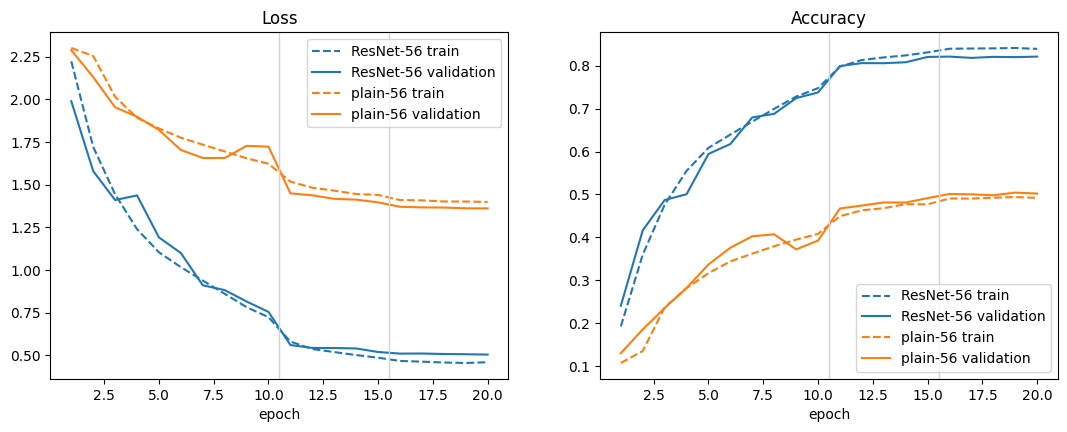

In [37]:
runs = [("ResNet-56", resnet, resnet_history, "C0"), ("plain-56", plain, plain_history, "C1")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, _, history, color in runs:
    epochs = [h["epoch"] for h in history]
    axes[0].plot(epochs, [h["train_loss"] for h in history], "--", color=color, label=f"{name} train")
    axes[0].plot(epochs, [h["val_loss"] for h in history], color=color, label=f"{name} validation")
    axes[1].plot(epochs, [h["train_acc"] for h in history], "--", color=color, label=f"{name} train")
    axes[1].plot(epochs, [h["val_acc"] for h in history], color=color, label=f"{name} validation")

axes[0].set_title("Loss")
axes[1].set_title("Accuracy")
for ax in axes:
    for m in milestones_for(EPOCHS):
        ax.axvline(m + 0.5, color="lightgray", linewidth=1)  # zmiana lr
    ax.set_xlabel("epoch")
    ax.legend()

plt.show()

In [38]:

for name, model, history, _ in runs:
    test_loss, test_acc = run_epoch(model, test_loader)
    print(f"{name:9s} | train accuracy {history[-1]['train_acc']:.1%} | val accuracy {history[-1]['val_acc']:.1%} | "
          f"test: loss {test_loss:.3f}, accuracy {test_acc:.1%}")
print("artykuł: ResNet-56 93.03% na teście (po 64k iteracjach, ok. 182 epokach)")

ResNet-56 | train accuracy 83.9% | val accuracy 82.1% | test: loss 0.523, accuracy 81.8%
plain-56  | train accuracy 49.2% | val accuracy 50.2% | test: loss 1.340, accuracy 51.8%
artykuł: ResNet-56 93.03% na teście (po 64k iteracjach, ok. 182 epokach)
